Text(0, 0.5, 'Metrica_Y')

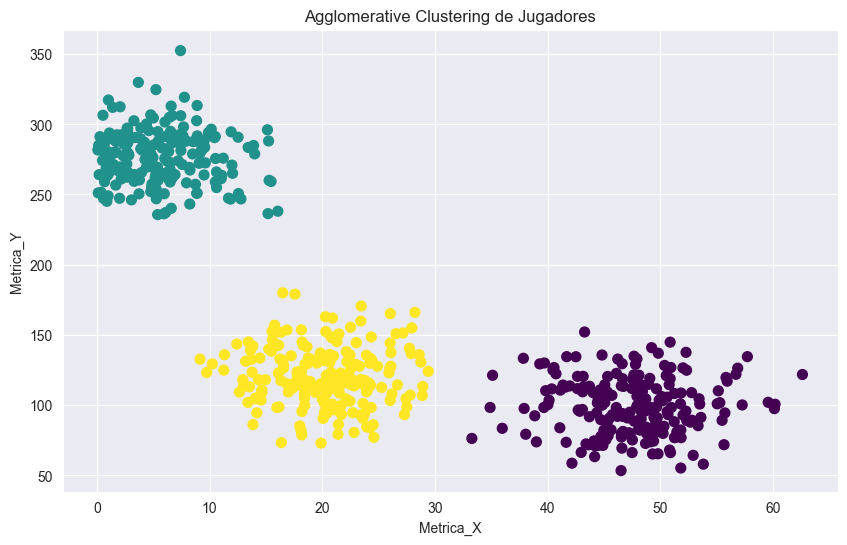

In [33]:
import pandas as pd
df = pd.read_csv('comportamiento_jugadores.csv')
df.head()

# /------------------------------------------
df_filtrado = df[df['Escenario'] == '1_Economia_Juego'].copy()
# df_filtrado.head(5)

# -----------------------------------------
from sklearn.preprocessing import StandardScaler
# Extraemos las dos métricas
X_crudo = df_filtrado[['Metrica_X', 'Metrica_Y']]
# Aplicamos el escalamiento antes de pasarlo al modelo
X_escalado = StandardScaler().fit_transform(X_crudo)


# -----------------------------------------
from sklearn.cluster import AgglomerativeClustering

clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_filtrado['Cluster'] = clustering.fit_predict(X_escalado)

# -----------------------------------------

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(df_filtrado['Metrica_X'], df_filtrado['Metrica_Y'], c=df_filtrado['Cluster'], cmap='viridis', s=50)
plt.title('Agglomerative Clustering de Jugadores')
plt.xlabel('Metrica_X')
plt.ylabel('Metrica_Y')